# **Linear Regression and Regularization — California Housing**


A structured, end-to-end regression workflow using Linear Regression, Ridge Regression, and Lasso Regression with scikit-learn.

## **Objective**

Predict the median house value for California districts from eight census-derived features, then compare ordinary least squares with regularized models.

### **What this notebook covers**

- Dataset inspection and concise exploratory data analysis (EDA)
- Train/test split and leakage-safe feature scaling
- Linear Regression baseline
- Evaluation with MAE, MSE, RMSE, and R²
- Residual and actual-vs-predicted diagnostics
- Ridge and Lasso regularization
- Final model comparison and conclusions

**Dataset note:** The target is expressed in units of $100,000. A target of 2.0 represents $200,000. This built-in dataset is for learning and benchmarking, not for estimating current market prices.

## **Workflow**

Load data → Inspect/EDA → Split → Train → Evaluate → Diagnose → Regularize → Compare

## **1. Import libraries**

Import the libraries used for data handling, visualization, preprocessing, model training, and evaluation.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## **2. Load and inspect the dataset**

The dataset contains eight numerical input features and a numerical target. Inspect the shape, data types, missing values, and summary statistics before modelling.

In [19]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

print(f"Dataset shape: {df.shape}")
print(f"Feature count: {X.shape[1]}")
print(f"Missing values: {df.isna().sum().sum()}")

display(df.head())

display(df.dtypes)


Dataset shape: (20640, 9)
Feature count: 8
Missing values: 0


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


,0
MedInc,float64
HouseAge,float64
AveRooms,float64
AveBedrms,float64
Population,float64
AveOccup,float64
Latitude,float64
Longitude,float64
MedHouseVal,float64


In [7]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


## **3. Exploratory data analysis (EDA)**

Use a small number of plots to understand the target distribution and its relationship with a useful feature. EDA is descriptive; it does not prove causation.

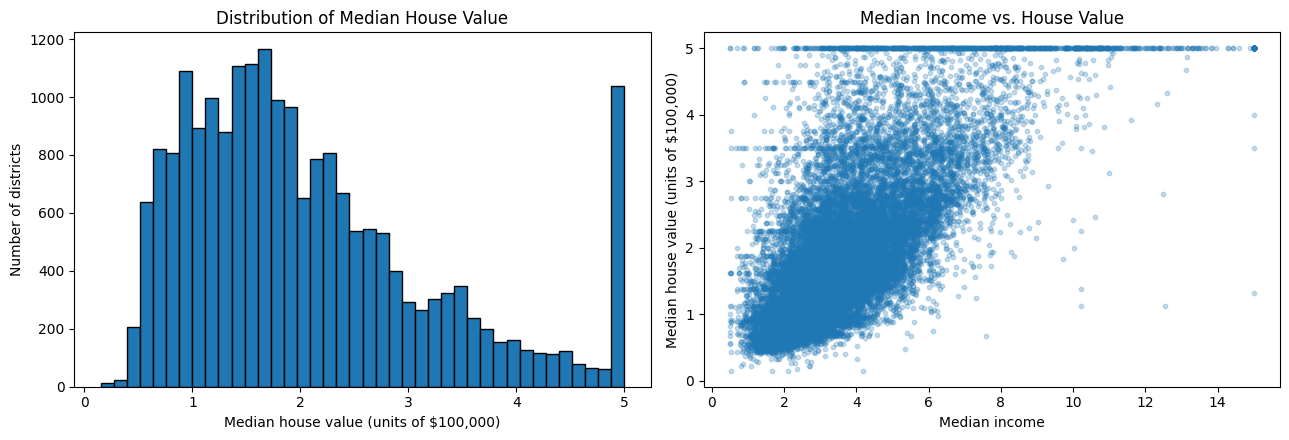

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(y, bins=40, edgecolor="black")
axes[0].set_title("Distribution of Median House Value")
axes[0].set_xlabel("Median house value (units of $100,000)")
axes[0].set_ylabel("Number of districts")

axes[1].scatter(X["MedInc"], y, alpha=0.25, s=10)
axes[1].set_title("Median Income vs. House Value")
axes[1].set_xlabel("Median income")
axes[1].set_ylabel("Median house value (units of $100,000)")

plt.tight_layout()
plt.show()


### Interpretation

1. Distribution of Median House Value: Most districts have median house values between 1 and 3 (in units of 100,000 dols). The large bar near 5 indicates that many values are capped at approximately $500,000.

2. Median Income vs. House Value: The scatter plot shows a positive relationship between median income and median house value. Generally, districts with higher median incomes tend to have higher house values. However, the relationship is not perfectly linear, and some variation is present.

## **4. Split the data**

Keep a test set aside for final evaluation. The models are fitted only on the training data; the test set is not used to learn model parameters. A fixed random_state makes the split reproducible.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training rows: {X_train.shape[0]}")
print(f"Testing rows:  {X_test.shape[0]}")


Training rows: 16512
Testing rows:  4128


## **5. Train a Linear Regression baseline**

Linear Regression estimates coefficients for a linear relationship between the input features and target. We start with it as a baseline before testing regularization.

In [10]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

coefficients = pd.Series(
    linear_model.coef_, index=X.columns, name="Coefficient"
).sort_values(key=abs, ascending=False)

display(coefficients.to_frame())
print(f"Intercept: {linear_model.intercept_:.4f}")


,Coefficient
AveBedrms,0.783145
MedInc,0.448675
Longitude,-0.433708
Latitude,-0.419792
AveRooms,-0.123323
HouseAge,0.009724
AveOccup,-0.003526
Population,-0.000002


Intercept: -37.0233


## **6. Evaluate model performance**

- MAE: average absolute error; lower is better.
- MSE: average squared error; lower is better and larger errors receive more weight.
- RMSE: square root of MSE; expressed in the target's units.
- R²: compares predictions with a baseline that predicts the test-set mean; closer to 1 is generally better, 0 is baseline-like, and a negative score is worse than that baseline.

Because the target is measured in units of 100,000 dollars, an MAE of 0.5 corresponds to an average absolute error of about $50,000.

In [11]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2_score(y_true, y_pred),
    }

linear_metrics = regression_metrics(y_test, y_pred_linear)
display(pd.DataFrame([linear_metrics], index=["Linear Regression"]).round(4))


,MAE,MSE,RMSE,R²
Linear Regression,0.5332,0.5559,0.7456,0.5758


**Actual vs. predicted values**

Points near the diagonal represent predictions close to the observed values. The sample table helps compare individual predictions.

,Actual value,Predicted value
20046,0.47700,0.719123
3024,0.45800,1.764017
15663,5.00001,2.709659
20484,2.18600,2.838926
9814,2.78000,2.604657
13311,1.58700,2.011754
7113,1.98200,2.645500
7668,1.57500,2.168755
18246,3.40000,2.740746
5723,4.46600,3.915615


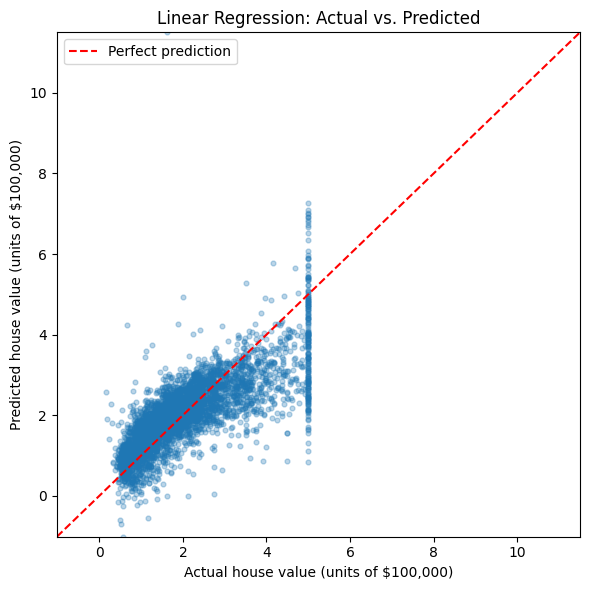

In [12]:
comparison = pd.DataFrame({
    "Actual value": y_test.to_numpy(),
    "Predicted value": y_pred_linear
}, index=y_test.index)

display(comparison.head(10))

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_linear, alpha=0.3, s=12)
limits = [
    min(y_test.min(), y_pred_linear.min()),
    max(y_test.max(), y_pred_linear.max())
]
plt.plot(limits, limits, "r--", label="Perfect prediction")
plt.xlim(limits)
plt.ylim(limits)
plt.xlabel("Actual house value (units of $100,000)")
plt.ylabel("Predicted house value (units of $100,000)")
plt.title("Linear Regression: Actual vs. Predicted")
plt.legend()
plt.tight_layout()
plt.show()


### Interpretation
Points closer to the red dashed line indicate more accurate predictions. The model captures the general trend but makes some errors, especially for higher house values.

**Residual analysis**

A residual is actual value − predicted value. Ideally, residuals are centred around zero and show no strong systematic pattern. A visible pattern can indicate that a linear model is missing some structure.

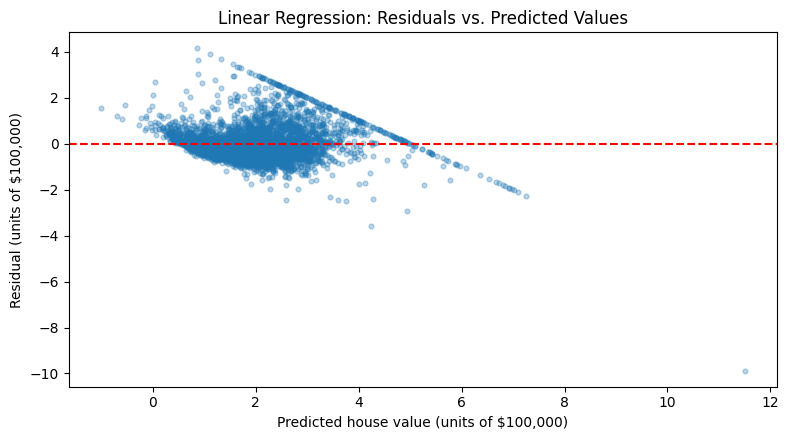

In [13]:
residuals = y_test.to_numpy() - y_pred_linear

plt.figure(figsize=(8, 4.5))
plt.scatter(y_pred_linear, residuals, alpha=0.3, s=12)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted house value (units of $100,000)")
plt.ylabel("Residual (units of $100,000)")
plt.title("Linear Regression: Residuals vs. Predicted Values")
plt.tight_layout()
plt.show()


## **7. Ridge and Lasso regularization**

Regularization penalizes large coefficients and can help reduce overfitting.

- Ridge (L2): shrinks coefficients toward zero, typically without making them exactly zero.

- Lasso (L1): can set some coefficients exactly to zero.

Scaling is important for regularized models because the penalty should not depend unfairly on feature units. Using a Pipeline ensures the scaler is fitted only on the training data, preventing data leakage. Here, alpha=1.0 is an illustrative setting, not a tuned optimum.

In [14]:
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge (alpha=1.0)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),
    "Lasso (alpha=0.01)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=0.01, max_iter=10000))
    ]),
}

predictions = {}
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    results.append({"Model": name, **regression_metrics(y_test, y_pred)})

results_df = pd.DataFrame(results).set_index("Model").sort_values("R²", ascending=False)
display(results_df.round(4))


,MAE,MSE,RMSE,R²
Model,,,,
Lasso (alpha=0.01),0.5353,0.5483,0.7404,0.5816
Ridge (alpha=1.0),0.5332,0.5559,0.7456,0.5758
Linear Regression,0.5332,0.5559,0.7456,0.5758


**Compare coefficients**

For this comparison, coefficients are taken from the estimator inside each pipeline. Since the features were standardized, the coefficients are on the standardized-feature scale and are comparable across these models.

In [15]:
coef_comparison = pd.DataFrame({
    name: pipeline.named_steps["model"].coef_
    for name, pipeline in models.items()
}, index=X.columns)

display(coef_comparison.round(4))


,Linear Regression,Ridge (alpha=1.0),Lasso (alpha=0.01)
MedInc,0.8544,0.8543,0.8010
HouseAge,0.1225,0.1226,0.1271
AveRooms,-0.2944,-0.2942,-0.1628
AveBedrms,0.3393,0.3390,0.2062
Population,-0.0023,-0.0023,-0.0000
AveOccup,-0.0408,-0.0408,-0.0306
Latitude,-0.8969,-0.8962,-0.7901
Longitude,-0.8698,-0.8691,-0.7557


## **8. Conclusion**

This notebook demonstrates a complete regression workflow: data inspection, EDA, a reproducible train/test split, Linear Regression, evaluation, residual diagnostics, and regularization with Ridge and Lasso.

Use the results table—not assumptions—to decide which model performed best on this test split. R² should be considered alongside MAE and RMSE, and the residual plot can reveal systematic errors. The selected alpha values have not been tuned, so the comparison is educational rather than a final hyperparameter search.

**Further improvements**

- Tune Ridge/Lasso alpha with cross-validation.
- Compare with DummyRegressor as a simple baseline.
- Use cross-validation for more stable performance estimates.
- Document the measured results in the repository README.

**Reproducibility**

The train/test split uses random_state=42. The dataset is loaded through scikit-learn's fetch_california_housing; an internet connection may be required the first time it is downloaded.